<a href="https://colab.research.google.com/github/yogya02/multidisciplinary-project/blob/main/rohan_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
SRC = '/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1'
for root, dirs, files in os.walk(SRC):
    print(root, '->', len(files), 'files', files[:5])

/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1 -> 0 files []
/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1/batch_1 -> 3 files ['data-00000-of-00001.arrow', 'state.json', 'dataset_info.json']
/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1/batch_2 -> 3 files ['data-00000-of-00001.arrow', 'state.json', 'dataset_info.json']
/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1/batch_3 -> 3 files ['data-00000-of-00001.arrow', 'state.json', 'dataset_info.json']
/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1/batch_4 -> 3 files ['data-00000-of-00001.arrow', 'state.json', 'dataset_info.json']
/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1/batch_5 -> 3 files ['data-00000-of-00001.arrow', 'state.json', 'dataset_info.json']
/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_10k_chunk_1/batch_6 -> 3 files ['data-00000-of-00001.arrow', 'state.json', 'dataset_info

In [ ]:
!pip install datasets -q
from datasets import load_from_disk

ds = load_from_disk(SRC + '/batch_1')
print(ds)
print(ds.features)

Dataset({
    features: ['tif', '__key__', '__url__'],
    num_rows: 1000
})
{'tif': {'bytes': Value('binary'), 'path': Value('string')}, '__key__': Value('string'), '__url__': Value('string')}


In [ ]:
!pip install rasterio -q
import numpy as np
from rasterio.io import MemoryFile

for i in [0, 1, 2]:
    print(ds[i]['__key__'], '|', ds[i]['__url__'])

with MemoryFile(ds[0]['tif']['bytes']) as mf:
    with mf.open() as src:
        a = src.read()
        print('shape:', a.shape, 'dtype:', a.dtype)
        print('unique values (first 10):', np.unique(a)[:10])

DEM/EMSR168_1_36SVD_x454885_y3880935_DEM | hf://datasets/ibm-esa-geospatial/ImpactMesh-Fire@00c6719952d591a7dcf6a8bfc1a245f2694c5e29/train/DEM.tar
DEM/EMSR168_2_36SVD_x451915_y3878185_DEM | hf://datasets/ibm-esa-geospatial/ImpactMesh-Fire@00c6719952d591a7dcf6a8bfc1a245f2694c5e29/train/DEM.tar
DEM/EMSR168_2_36SVD_x451915_y3880745_DEM | hf://datasets/ibm-esa-geospatial/ImpactMesh-Fire@00c6719952d591a7dcf6a8bfc1a245f2694c5e29/train/DEM.tar
shape: (1, 256, 256) dtype: int16
unique values (first 10): [ 94  97  98 102 103 104 105 107 108 109]


In [ ]:
for b in range(1, 11):
    d = load_from_disk(f'{SRC}/batch_{b}')
    first = d[0]['__url__'].split('@')[-1].split('/', 1)[-1]
    last = d[len(d)-1]['__url__'].split('@')[-1].split('/', 1)[-1]
    print(f'batch_{b}:', len(d), 'rows | first:', first, '| last:', last)

batch_1: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_2: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_3: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_4: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_5: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_6: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_7: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_8: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_9: 1000 rows | first: train/DEM.tar | last: train/DEM.tar
batch_10: 1000 rows | first: train/DEM.tar | last: train/DEM.tar


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/Wildfire-Detection/data'))
print(os.listdir('/content/drive/MyDrive/Wildfire-Detection'))

['raw', 'processed', 'impactmesh_10k_chunk_1']
['screenshots', 'notebooks', 'results', 'data', 'report', 'Review-I.docx']


In [ ]:
D = '/content/drive/MyDrive/Wildfire-Detection/data'
for name in ['raw', 'processed']:
    print('==', name)
    for root, dirs, files in os.walk(f'{D}/{name}'):
        depth = root[len(D):].count('/')
        if depth <= 3:
            print(root[len(D):], '->', len(dirs), 'folders,', len(files), 'files', files[:3])

== raw
/raw -> 0 folders, 0 files []
== processed
/processed -> 0 folders, 0 files []


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
SRC = '/content/drive/MyDrive/Wildfire-Detection/data/impactmesh_fire'
for root, dirs, files in os.walk(SRC):
    depth = root[len(SRC):].count('/')
    if depth <= 2:
        print(root[len(SRC):] or '/', '->', len(dirs), 'folders,', len(files), 'files', files[:6])

Mounted at /content/drive
/ -> 4 folders, 0 files []
/split -> 0 folders, 5 files ['impactmesh_fire_test_holdout.txt', 'impactmesh_fire_test_seen_events.txt', 'impactmesh_fire_val.txt', 'impactmesh_fire_test.txt', 'impactmesh_fire_train.txt']
/val -> 0 folders, 3 files ['S2L2A.tar', 'MASK.tar', 'S2RGB.tar']
/train -> 0 folders, 2 files ['MASK.tar', 'S2RGB.tar']
/test -> 0 folders, 2 files ['MASK.tar', 'S2RGB.tar']


In [ ]:
!pip install "zarr<3" rasterio -q
import tarfile, glob

DATA = '/content/impactmesh'
os.makedirs(DATA + '/val', exist_ok=True)

for name in ['MASK.tar', 'S2RGB.tar']:
    print('Extracting val/' + name)
    with tarfile.open(f'{SRC}/val/{name}') as tf:
        tf.extractall(DATA + '/val/' + name.replace('.tar', ''))

for root, dirs, files in os.walk(DATA):
    print(root, '->', len(files), 'files', files[:3])

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.3/211.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 82.0 MB/s eta 0:00:00
Extracting val/MASK.tar


/tmp/ipykernel_939/1703840214.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(DATA + '/val/' + name.replace('.tar', ''))


Extracting val/S2RGB.tar
/content/impactmesh -> 0 files []
/content/impactmesh/val -> 0 files []
/content/impactmesh/val/S2RGB -> 0 files []
/content/impactmesh/val/S2RGB/S2RGB -> 1864 files ['EMSR248_2_29TQF_x716895_y4583585_S2RGB.tif', 'EMSR571_2_14QML_x467655_y2553625_S2RGB.tif', 'EMSR209_1_29SPB_x693555_y4118795_S2RGB.tif']
/content/impactmesh/val/MASK -> 0 files []
/content/impactmesh/val/MASK/MASK -> 1864 files ['EMSR248_3_29TQE_x276905_y4480515_annotation_wildfire.tif', 'EMSR213_15_33SXD_x614285_y4356765_annotation_wildfire.tif', 'EMSR837_3_30TUN_x340225_y4759575_annotation_wildfire.tif']


In [ ]:
import rasterio, numpy as np, pandas as pd

MASKDIR = DATA + '/val/MASK/MASK'
OUT = '/content/outputs'
os.makedirs(OUT, exist_ok=True)

rows, bad_files, bad_values, shapes = [], [], [], set()
for f in sorted(os.listdir(MASKDIR)):
    try:
        with rasterio.open(f'{MASKDIR}/{f}') as r:
            m = r.read(1)
        shapes.add(m.shape)
        if not set(np.unique(m)) <= {-1, 0, 1}:
            bad_values.append(f)
        valid = int((m != -1).sum())
        fire = int((m == 1).sum())
        rows.append(dict(id=f, fire_px=fire, valid_px=valid, frac=fire / max(valid, 1)))
    except Exception as e:
        bad_files.append(f)

df = pd.DataFrame(rows)
df['has_fire'] = df.fire_px > 0

print('Y = total val chips:', len(df))
print('X = val chips with fire:', int(df.has_fire.sum()))
print('Z = mean fire fraction:', round(df.frac.mean(), 5))
print('Fire pixels overall:', round(df.fire_px.sum() / df.valid_px.sum(), 5))
print('Mask shapes:', shapes)
print('Corrupted masks:', len(bad_files), bad_files)
print('Masks with unexpected values:', len(bad_values), bad_values[:5])

Y = total val chips: 1864
X = val chips with fire: 1065
Z = mean fire fraction: 0.28338
Fire pixels overall: 0.28303
Mask shapes: {(256, 256)}
Corrupted masks: 0 []
Masks with unexpected values: 0 []


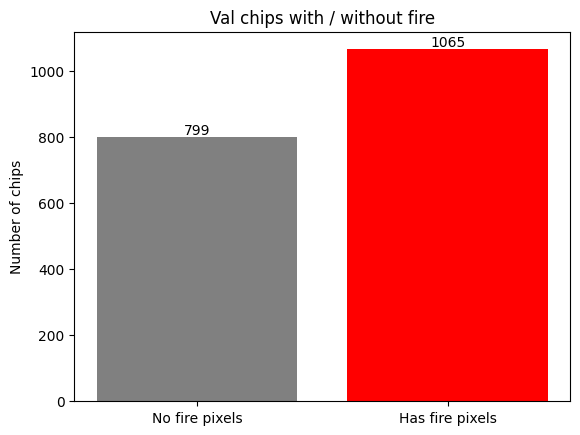

In [ ]:
import matplotlib.pyplot as plt

counts = [int((~df.has_fire).sum()), int(df.has_fire.sum())]
plt.bar(['No fire pixels', 'Has fire pixels'], counts, color=['gray', 'red'])
plt.title('Val chips with / without fire')
plt.ylabel('Number of chips')
for i, c in enumerate(counts):
    plt.text(i, c, str(c), ha='center', va='bottom')
plt.savefig(OUT + '/class_balance.png')
plt.show()

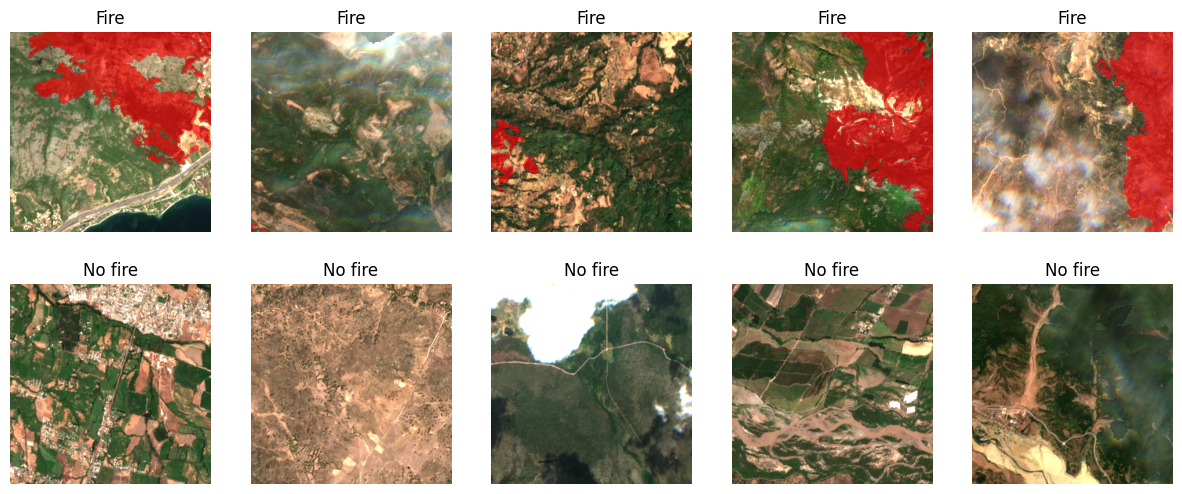

In [ ]:
import random

RGBDIR = DATA + '/val/S2RGB/S2RGB'
fire_ids = df[df.has_fire].id.tolist()
nofire_ids = df[~df.has_fire].id.tolist()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row, (name, pool) in enumerate([('Fire', fire_ids), ('No fire', nofire_ids)]):
    for col, f in enumerate(random.sample(pool, 5)):
        sid = f.replace('_annotation_wildfire.tif', '')
        with rasterio.open(f'{RGBDIR}/{sid}_S2RGB.tif') as r:
            img = r.read()
        img = np.transpose(img[:3], (1, 2, 0)).astype('float32')
        img = np.clip(img / np.percentile(img, 99), 0, 1)   # brighten for display
        with rasterio.open(f'{MASKDIR}/{f}') as r:
            m = r.read(1)
        axes[row, col].imshow(img)
        axes[row, col].imshow(np.ma.masked_where(m != 1, m), cmap='autumn', alpha=0.6)
        axes[row, col].set_title(name)
        axes[row, col].axis('off')
plt.savefig(OUT + '/samples.png')
plt.show()

In [ ]:
import zarr, glob

os.makedirs(DATA + '/val/S2L2A', exist_ok=True)
print('Extracting val/S2L2A.tar (this is the slow one)')
with tarfile.open(f'{SRC}/val/S2L2A.tar') as tf:
    tf.extractall(DATA + '/val/S2L2A')

z_paths = sorted(glob.glob(DATA + '/val/S2L2A/**/*_S2L2A.zarr.zip', recursive=True))
print('Multispectral val chips:', len(z_paths))

store = zarr.ZipStore(z_paths[0], mode='r')
g = zarr.open(store, mode='r')
print(g.tree() if hasattr(g, 'tree') else g)
store.close()

Extracting val/S2L2A.tar (this is the slow one)


/tmp/ipykernel_939/3168614275.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(DATA + '/val/S2L2A')


Multispectral val chips: 1864
/
 ├── SCL (4, 256, 256) float32
 ├── band (12,) <U6
 ├── bands (4, 12, 256, 256) int16
 ├── cloud_mask (4, 256, 256) float32
 ├── data_mask (4,) int8
 ├── nan_mask (4, 256, 256) int8
 ├── spatial_ref () int64
 ├── time (4,) int64
 ├── x (256,) float64
 └── y (256,) float64


In [ ]:
import shutil
DEST = '/content/drive/MyDrive/Wildfire-Detection/results'
os.makedirs(DEST, exist_ok=True)
for f in ['class_balance.png', 'samples.png']:
    shutil.copy(f'{OUT}/{f}', f'{DEST}/{f}')
print(os.listdir(DEST))

['class_balance.png', 'samples.png']
